basic data check plot of 
[text](Testfahrt_1.txt) 
[text](Testfahrt_2_D=1.txt) 
[text](Testfahrt_3_schwingen.txt)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Columns of the measurement section (semicolon separated).
COLUMNS = ["Time/ms", "QEI1/steps", "QEI2/steps", "d/cm", "Mot0/%"]
HEADER_LINE = "Time/ms;QEI1/steps;QEI2/steps;d/cm;Mot0/%"


def load_testfahrt(path):
    """Load a Testfahrt logfile.

    The files start with a variable-length text header. The actual
    measurement data begins right after the line
    'Time/ms;QEI1/steps;QEI2/steps;d/cm;Mot0/%'. We locate that line and
    parse everything after it as semicolon-separated values.
    """
    path = Path(path)
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

    # Find the data header line.
    header_idx = next(i for i, line in enumerate(lines)
                      if line.strip().startswith("Time/ms;QEI1"))

    df = pd.read_csv(
        path,
        sep=";",
        skiprows=header_idx + 1,   # skip header text + the column line
        names=COLUMNS,
        skipinitialspace=True,
        engine="python",
        on_bad_lines="skip",
    )
    # Drop rows that failed to parse (e.g. stray text) and coerce to numbers.
    df = df.apply(pd.to_numeric, errors="coerce").dropna(how="all")
    df = df.dropna(subset=["Time/ms"]).reset_index(drop=True)
    return df


In [17]:
files = {
    "Testfahrt 1": "Testfahrt_1.txt",
    "Testfahrt 2 (D=1)": "Testfahrt_2_D=1.txt",
    "Testfahrt 3 (schwingen)": "Testfahrt_3_schwingen.txt",
}

data = {label: load_testfahrt(fname) for label, fname in files.items()}

for label, df in data.items():
    print(f"{label}: {len(df)} samples, t = {df['Time/ms'].min():.0f}..{df['Time/ms'].max():.0f} ms")
data["Testfahrt 1"].head()

Testfahrt 1: 1500 samples, t = 0..2998 ms
Testfahrt 2 (D=1): 1500 samples, t = 0..2998 ms
Testfahrt 3 (schwingen): 1500 samples, t = 0..2998 ms


,Time/ms,QEI1/steps,QEI2/steps,d/cm,Mot0/%
0,0,0,0,26.5,18
1,2,0,0,26.5,18
2,4,0,0,27.0,18
3,6,0,0,27.0,18
4,8,0,0,27.0,18


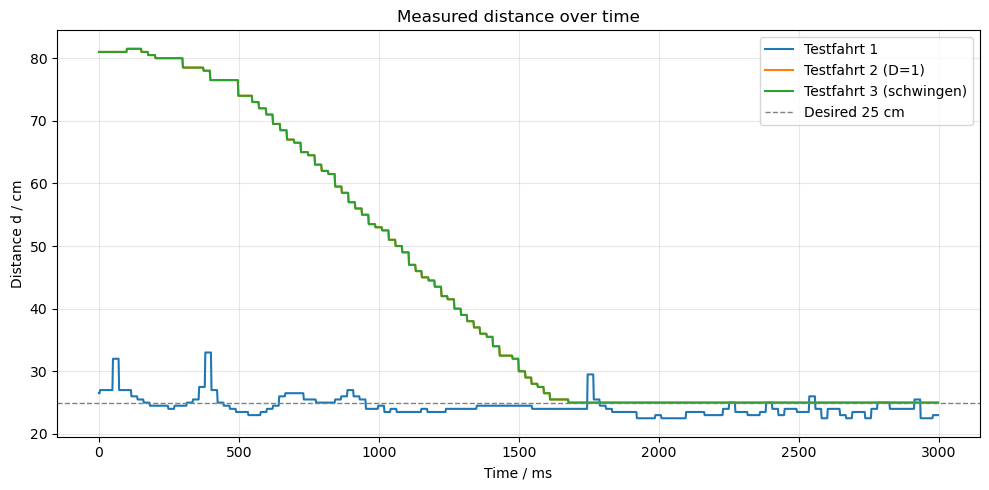

In [18]:
# Distance d/cm over time for all three drives.
fig, ax = plt.subplots(figsize=(10, 5))
for label, df in data.items():
    ax.plot(df["Time/ms"], df["d/cm"], label=label)

ax.axhline(25.0, color="gray", linestyle="--", linewidth=1, label="Desired 25 cm")
ax.set_xlabel("Time / ms")
ax.set_ylabel("Distance d / cm")
ax.set_title("Measured distance over time")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

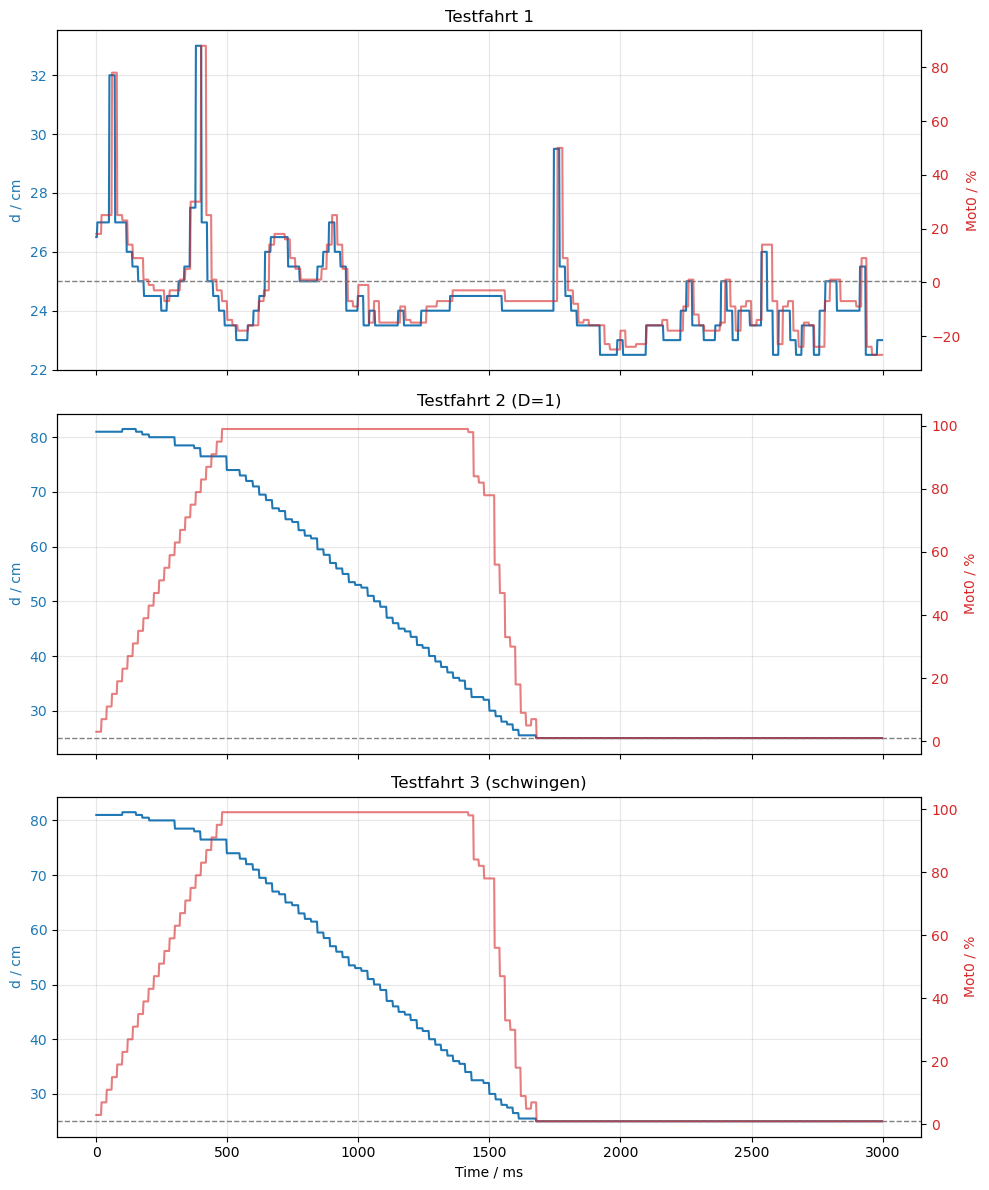

In [19]:
# Per-drive overview: distance, motor output and encoder steps.
fig, axes = plt.subplots(len(data), 1, figsize=(10, 4 * len(data)), sharex=True)

for ax, (label, df) in zip(axes, data.items()):
    ax.plot(df["Time/ms"], df["d/cm"], color="tab:blue", label="d / cm")
    ax.axhline(25.0, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("d / cm", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.set_title(label)
    ax.grid(True, alpha=0.3)

    ax2 = ax.twinx()
    ax2.plot(df["Time/ms"], df["Mot0/%"], color="tab:red", alpha=0.6, label="Mot0 / %")
    ax2.set_ylabel("Mot0 / %", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

axes[-1].set_xlabel("Time / ms")
plt.tight_layout()
plt.show()

## T4 control-loop simulation (`RTP5.xlsx`)

Simulated step response of the closed control loop: `w` = reference / setpoint,
`x` = controlled variable, `y_sat` = saturated actuator output (0–100 %).

151 samples, t = 0.0..3.0 s
columns: ['time', 'w', 'y_sat', 'x']


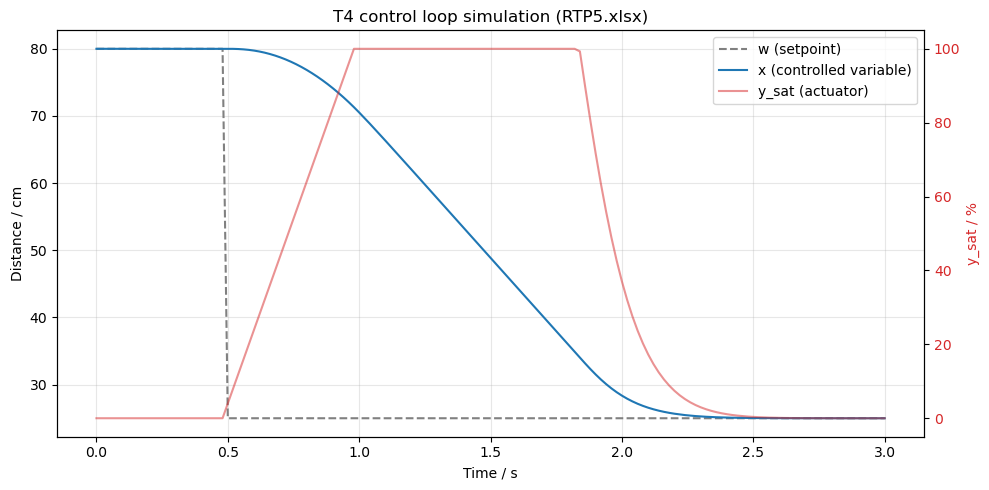

In [20]:
# Load the T4 control-loop simulation from the Excel workbook.
sim = pd.read_excel("RTP5.xlsx", sheet_name=0)
print(f"{len(sim)} samples, t = {sim['time'].min()}..{sim['time'].max()} s")
print("columns:", list(sim.columns))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sim["time"], sim["w"], color="gray", linestyle="--", label="w (setpoint)")
ax.plot(sim["time"], sim["x"], color="tab:blue", label="x (controlled variable)")
ax.set_xlabel("Time / s")
ax.set_ylabel("Distance / cm")
ax.set_title("T4 control loop simulation (RTP5.xlsx)")
ax.grid(True, alpha=0.3)

# Actuator signal on a second axis (different scale: percent).
ax2 = ax.twinx()
ax2.plot(sim["time"], sim["y_sat"], color="tab:red", alpha=0.5, label="y_sat (actuator)")
ax2.set_ylabel("y_sat / %", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# Merge legends from both axes.
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, loc="best")

plt.tight_layout()
plt.show()

## Testfahrt 2 (D=1) — all variables (scientific style)

Every logged channel of `Testfahrt_2_D=1.txt` on a shared time axis: distance
`d`, motor output `Mot0`, and the two wheel encoders `QEI1` / `QEI2`.

saved C:\Users\janis\OneDrive\Dokumente\01-projects\RTP-SoSe-2026-Praktikum\RTP-T5-SoSe2026\01_RTP-Ausarbeitung\figure\Testfahrt_2_D1.pdf


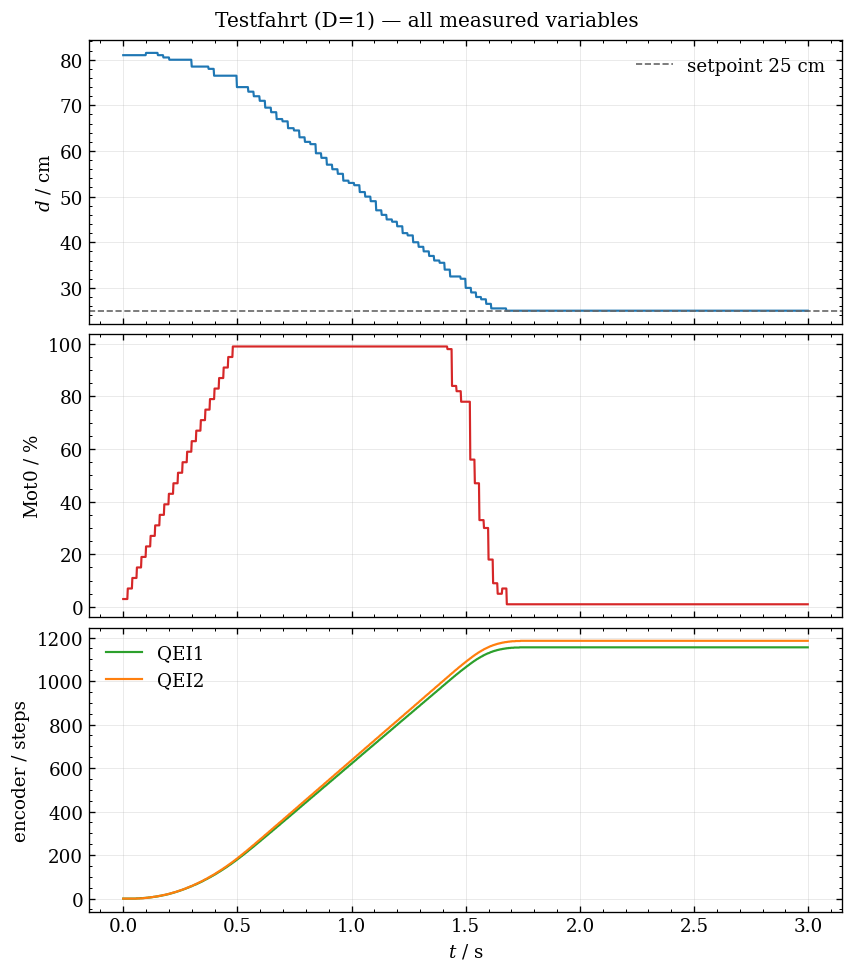

In [21]:
# Scientific-style rcParams, scoped so they don't affect the other figures.
science_style = {
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "serif",
    "font.size": 11,
    "mathtext.fontset": "dejavuserif",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "lines.linewidth": 1.3,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "legend.frameon": False,
}

df2 = data["Testfahrt 2 (D=1)"]
t = df2["Time/ms"] / 1000.0  # ms -> s for a cleaner axis

with plt.rc_context(science_style):
    fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True, constrained_layout=True)

    # (1) Distance with the 25 cm setpoint.
    axes[0].plot(t, df2["d/cm"], color="tab:blue")
    axes[0].axhline(25.0, color="0.4", linestyle="--", linewidth=1, label="setpoint 25 cm")
    axes[0].set_ylabel(r"$d$ / cm")
    axes[0].legend(loc="upper right")

    # (2) Motor output.
    axes[1].plot(t, df2["Mot0/%"], color="tab:red")
    axes[1].set_ylabel(r"$\mathrm{Mot0}$ / %")

    # (3) Both wheel encoders.
    axes[2].plot(t, df2["QEI1/steps"], color="tab:green", label="QEI1")
    axes[2].plot(t, df2["QEI2/steps"], color="tab:orange", label="QEI2")
    axes[2].set_ylabel("encoder / steps")
    axes[2].legend(loc="upper left")

    axes[-1].set_xlabel(r"$t$ / s")
    fig.suptitle("Testfahrt (D=1) — all measured variables", fontsize=12)

    # Export as vector PDF into the LaTeX writeup's figure folder.
    # ('=' dropped from the name so \includegraphics doesn't choke on it.)
    fig_dir = Path("../01_RTP-Ausarbeitung/figure")
    fig_dir.mkdir(parents=True, exist_ok=True)
    pdf_path = fig_dir / "Testfahrt_2_D1.pdf"
    fig.savefig(pdf_path)
    print(f"saved {pdf_path.resolve()}")

    plt.show()

## Task (i): recorded test-drive vs. simulation

One graph comparing the **recorded test-drive** (`Testfahrt_2_D=1.txt`) against the
**simulated** control loop (`RTP5.xlsx`) for the three requested quantities:

| quantity | recorded | simulated |
|----------|----------|-----------|
| distance to obstacle | `d/cm` | `x` |
| travelled distance | wheel encoders `QEI1/QEI2` | `x₀ − x` |
| duty cycle of motor 0 | `Mot0/%` | `y_sat` |

The encoder steps are converted to a travelled distance with the wheel-odometry
relation from the previous experiment (T4): `s = (steps / 360°) · π · d_R`,
`d_R = 5.6 cm`. Recorded series are drawn **solid**, simulated series **dashed**.

saved C:\Users\janis\OneDrive\Dokumente\01-projects\RTP-SoSe-2026-Praktikum\RTP-T5-SoSe2026\01_RTP-Ausarbeitung\figure\Comparison_recorded_vs_simulation.pdf


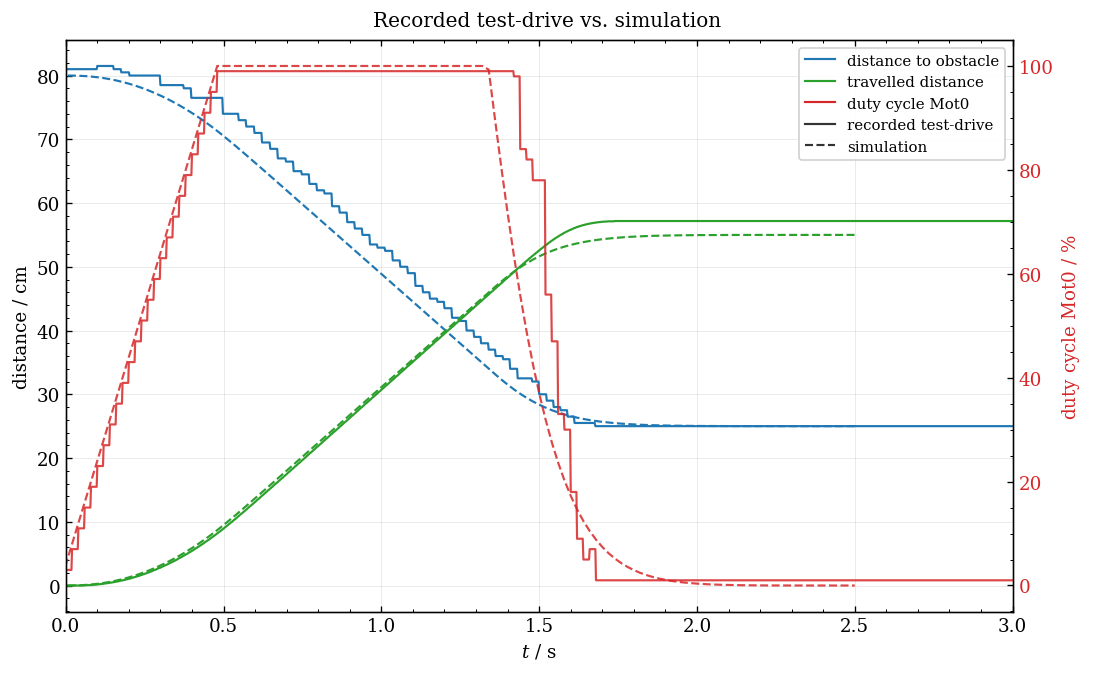

In [22]:
from matplotlib.lines import Line2D
import numpy as np

# --- Wheel odometry: QEI steps -> travelled distance (from experiment T4) -----
#   s = (steps / 360 deg) * pi * d_R,   d_R = 5.6 cm,   and   d = d_0 - s
WHEEL_DIAMETER_CM = 5.6
STEPS_PER_REV = 360
CM_PER_STEP = np.pi * WHEEL_DIAMETER_CM / STEPS_PER_REV

# --- Recorded test-drive (real-world data) ------------------------------------
rec = data["Testfahrt 2 (D=1)"]
t_rec = rec["Time/ms"] / 1000.0                              # ms -> s
dist_rec = rec["d/cm"]                                       # distance to obstacle
trav_rec = (rec["QEI1/steps"] + rec["QEI2/steps"]) / 2 * CM_PER_STEP  # mean wheel
duty_rec = rec["Mot0/%"]                                     # duty cycle Mot0

# --- Simulation ---------------------------------------------------------------
# The simulated reference steps 0.5 s into the run, whereas the recording starts
# at motion onset. Shift the simulation onto the recording's time base so the
# step responses overlay. Set SIM_T_SHIFT = 0.0 to inspect the raw offset.
SIM_T_SHIFT = -0.5
t_sim = sim["time"] + SIM_T_SHIFT
dist_sim = sim["x"]                                          # distance to obstacle
trav_sim = sim["x"].iloc[0] - sim["x"]                       # travelled = x0 - x
duty_sim = sim["y_sat"]                                      # duty cycle

C_DIST, C_TRAV, C_DUTY = "tab:blue", "tab:green", "tab:red"

with plt.rc_context(science_style):
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    axr = ax.twinx()           # right axis: duty cycle in %
    axr.grid(False)

    # distance to obstacle (left axis, cm)
    ax.plot(t_rec, dist_rec, color=C_DIST, ls="-")
    ax.plot(t_sim, dist_sim, color=C_DIST, ls="--")
    # travelled distance (left axis, cm)
    ax.plot(t_rec, trav_rec, color=C_TRAV, ls="-")
    ax.plot(t_sim, trav_sim, color=C_TRAV, ls="--")
    # duty cycle of motor 0 (right axis, %)
    axr.plot(t_rec, duty_rec, color=C_DUTY, ls="-", alpha=0.85)
    axr.plot(t_sim, duty_sim, color=C_DUTY, ls="--", alpha=0.85)

    ax.set_xlim(0, 3)
    ax.set_xlabel(r"$t$ / s")
    ax.set_ylabel("distance / cm")
    axr.set_ylabel(r"duty cycle $\mathrm{Mot0}$ / %", color=C_DUTY)
    axr.tick_params(axis="y", labelcolor=C_DUTY)

    # Combined legend: colour = quantity, line style = data source.
    legend_handles = [
        Line2D([0], [0], color=C_DIST, label="distance to obstacle"),
        Line2D([0], [0], color=C_TRAV, label="travelled distance"),
        Line2D([0], [0], color=C_DUTY, label="duty cycle Mot0"),
        Line2D([0], [0], color="0.2", ls="-",  label="recorded test-drive"),
        Line2D([0], [0], color="0.2", ls="--", label="simulation"),
    ]
    ax.legend(handles=legend_handles, loc="upper right",
              frameon=True, framealpha=0.9, fontsize=9)

    fig.suptitle("Recorded test-drive vs. simulation", fontsize=12)

    # Export as vector PDF for the LaTeX writeup (task i).
    fig_dir = Path("../01_RTP-Ausarbeitung/figure")
    fig_dir.mkdir(parents=True, exist_ok=True)
    pdf_path = fig_dir / "Comparison_recorded_vs_simulation.pdf"
    fig.savefig(pdf_path)
    print(f"saved {pdf_path.resolve()}")

    plt.show()